# Workshop 2: Classification


To build a proper machine learning model we need clean data. However, almost all the datasets are dirty due to noise, outliers. It is also important to know the data to use the appropriate machine learning algorithm. Thus, in this exercise, we will try to explore the data, clean the data, find insights, and finally apply machine learning models.

There are so many data cleaning techniques, however, we will only focus on the most basic operations
There are some questions prepared for you to answer. Please double click on those cells and answer them.
Check out this [video](https://www.youtube.com/watch?v=HW29067qVWk) (From 4:30 seconds) to learn how to use Jupyter Notebook more efficiently.

You can also use google colab as well. It is a free online platform provided by Google to execute ipynb files. You don't have to install anything in your local machine. You just need an internet connection and you are ready to go. A short youtube survey will help you to understand all the basic
usage of **Google Colab**.


# Part - 1

### Titanic Dataset

Some notes for the dataset.
**Feature Names**

**pclass**: A proxy for socio-economic status (SES)
1 = Upper
2 = Middle
3 = Lower
**age**: Age is fractional if less than 1. If the age is estimated, is it in the form of xx.5
**sibsp**: The dataset defines family relations in this way __Sibling__ and __Spouse__.
**parch**: The dataset defines family relations in this way... Parent and Child. Some children travelled only with a nanny, therefore parch=0 for them.
Our Task is to explore the data, clean it properly to feed in the machine learning model and finally predict if a passenger has survived or not, utilizing the best predictive model.
#### Contents:
1. Read In and Explore the Data
2. Data Analysis
3. Data Visualization
4. Cleaning Data
5. Train Machine Learning Models
6. Choosing the Best Model

## 1) Import Necessary Libraries
The first thing you have to do is to import necessary modules.

In [57]:
#data analysis libraries 
import numpy as np
import pandas as pd

#visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#ignore warnings
import warnings
warnings.filterwarnings('ignore')

## 2) Read in and Explore the Data 
It's time to read in our training and testing data using `pd.read_csv`

**Mohammed Grech 08/10/2026**

The lecturer advised us to use the `train.csv` file provided on CANVAS, as the `test.csv` file was identical to the `train.csv` dataset. Therefore, some of the code provided in the original notebook will be omitted, and the preprocessing will be performed on the `train.csv` dataset.


In [58]:
#import train CSV files
train = pd.read_csv("train.csv")

## 3) Data Analysis
We will try to observe some key insights of the data. Answer the following questions:

**Q.** What is difference between .head() and .sample() function ? Hint: Check Pandas Documentation

**Mohammed Grech 10/10/2026**:
The .head() function returns the first 5 rows of a dataset by default, based on the current order of the data. Additionally, a number can also be specified to return more or fewer rows. For example, train.head(15) returns the first 15 rows.

The .sample() function, on the other hand, returns random rows from the dataset, regardless of the order of the data. This fucntion can also take a number as an argument to specify how many random rows to return. For example, train.sample(15) returns 15 randomly selected rows.

Therefore, the main difference is that .head() shows the first rows of the dataset, while .sample() selects random rows from the dataset.

**Q.** There are a total of 714 values for Age feature in the training set. What is the percentage of missing values in Age column?

In [59]:
# Total number of missing values in the "Age" column divided by the total number of rows in the train dataset, 
# multiplied by 100 to get the percentage
missing_age = train["Age"].isna().sum() / len(train) * 100

print(f"Missing Age values: {missing_age:.2f}%")

Missing Age values: 19.87%


**Q.** What is the percentage of missing values in the Cabin feature? Note: If the percentage of the missing value for the Cabin is high, it would be hard to fill in the missing values. Thus, drop the column may be a good idea.

**Mohammed Grech 06/10/2026:**

At a later stage, the instruction indicates that the cabin column needs to be dropped. Hence it will be dropped at **section 5 Cleaning Data** tather than in this section.

In [60]:
missing_cabin =train["Cabin"].isna().sum() / len(train) * 100
print(f"Missing Cabin values: {missing_cabin:.2f}%")

Missing Cabin values: 77.10%


### Few Hypothesis (Initial Assumption):
* Sex: Females are more likely to survive.
* Pclass: People of higher socioeconomic class are more likely to survive.
* SibSp/Parch: People traveling alone are more likely to survive.
* Age: Young children are more likely to survive.

## 4) Data Visualization
To see if our hypothesis is correct or not, we have to visualize the data

### Sex Feature
This one is done for you.

Percentage of females who survived: 74.20382165605095
Percentage of males who survived: 18.890814558058924


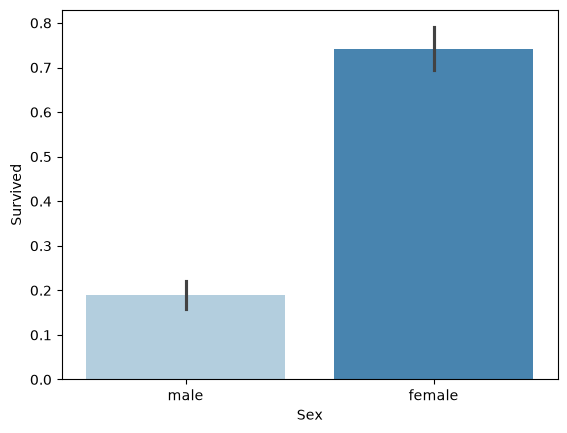

In [61]:
#draw a bar plot of survival by sex
sns.barplot(x="Sex", y="Survived", data=train, palette = "Blues")

#print percentages of females vs. males that survive
print("Percentage of females who survived:", train["Survived"][train["Sex"] == 'female'].value_counts(normalize = True)[1]*100)

print("Percentage of males who survived:", train["Survived"][train["Sex"] == 'male'].value_counts(normalize = True)[1]*100)

Our first hypothesis seems correct. Females have a much higher chance of survival than males.

### Pclass Feature

Percentage of upper-class who survived: 62.96%
Percentage of middle-class who survived: 47.28%
Percentage of lower-class who survived: 24.24%


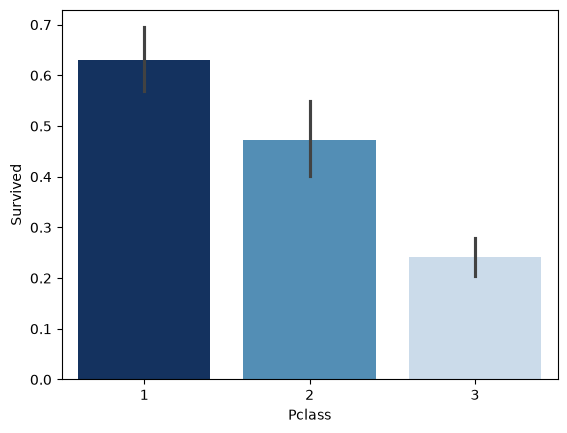

In [62]:
# Add your code here
sns.barplot(
    data=train,
    x="Pclass",
    y="Survived",
    hue="Pclass",
    palette={1: "#08306b", 2: "#4292c6", 3: "#c6dbef"},
    legend=False
)

#percentages of upper-class vs middle-class vs lower-class that survived
print("Percentage of upper-class who survived:", f"{train['Survived'][train['Pclass'] == 1].value_counts(normalize = True)[1]*100:.2f}%")

print("Percentage of middle-class who survived:", f"{train['Survived'][train['Pclass'] == 2].value_counts(normalize = True)[1]*100:.2f}%")

print("Percentage of lower-class who survived:", f"{train['Survived'][train['Pclass'] == 3].value_counts(normalize = True)[1]*100:.2f}%")

Add your explanation here:

**Mohammed Grech 10/10/2026**:
According to the above analysis, upper-class passengers had the highest survival rate at 62.96%, followed by middle-class passengers at 47.28%. Lastly, lower-class passengers had the lowest survival rate at 24.24%.

### SibSp Feature

SibSp/Parch: People traveling alone are more likely to survive.

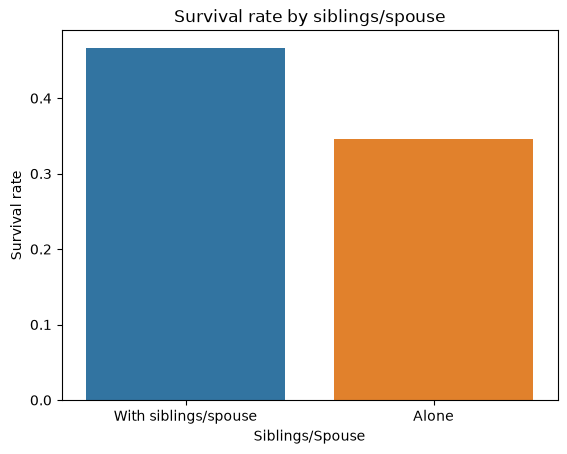

Alone - survived: 34.5%
Alone - did not survive: 65.5%

With siblings/spouse - survived: 46.6%
With siblings/spouse - did not survive: 53.4%


In [63]:
# Add your code here
train["SibSpGroup"] = (
    (train["SibSp"] == 0)
    .map({True: "Alone", False: "With siblings/spouse"})
)

sns.barplot(data=train, x="SibSpGroup", y="Survived", hue="SibSpGroup", errorbar=None)

plt.xlabel("Siblings/Spouse")
plt.ylabel("Survival rate")
plt.title("Survival rate by siblings/spouse")
plt.show()

survival_rate = train.groupby("SibSpGroup")["Survived"].mean()

print(f"Alone - survived: {survival_rate['Alone']:.1%}")
print(f"Alone - did not survive: {1 - survival_rate['Alone']:.1%}\n")

print(f"With siblings/spouse - survived: {survival_rate['With siblings/spouse']:.1%}")
print(f"With siblings/spouse - did not survive: {1 - survival_rate['With siblings/spouse']:.1%}")

Add your explanation here:

**Mohammed Grech 10/10/2026**:
Based on the above findings, the hypothesis that “People travelling alone are more likely to survive” is not supported. The results show that passengers travelling with family members such as siblings and/or spouses had a higher survival rate of 46.6%, compared to 34.5% for passengers travelling alone.

### Parch Feature

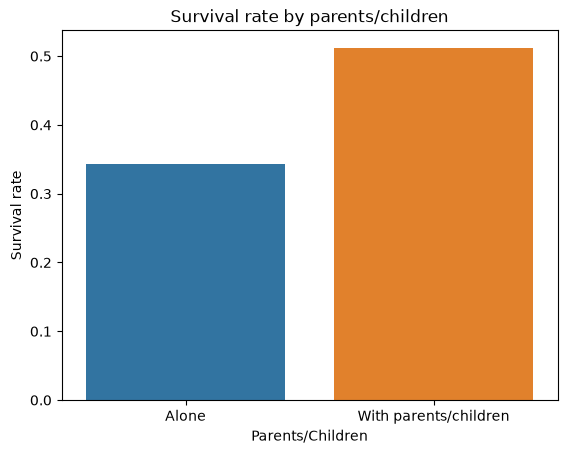

Alone - survived: 34.4%
Alone - did not survive: 65.6%

With parents/children - survived: 51.2%
With parents/children - did not survive: 48.8%


In [64]:
# Add your code here
train["ParchGroup"] = (
    (train["Parch"] == 0)
    .map({True: "Alone", False: "With parents/children"})
)

sns.barplot(data=train, x="ParchGroup", y="Survived", hue="ParchGroup", errorbar=None)

plt.xlabel("Parents/Children")
plt.ylabel("Survival rate")
plt.title("Survival rate by parents/children")
plt.show()

survival_rate = train.groupby("ParchGroup")["Survived"].mean()

print(f"Alone - survived: {survival_rate['Alone']:.1%}")
print(f"Alone - did not survive: {1 - survival_rate['Alone']:.1%}\n")

print(f"With parents/children - survived: {survival_rate['With parents/children']:.1%}")
print(f"With parents/children - did not survive: {1 - survival_rate['With parents/children']:.1%}")

Add your explanation here:

Similar to the results obtained for SibSp, the hypothesis is once again not supported. The results show that passengers travelling with parents and/or children had a higher survival rate of 51.2%, compared to 34.4% for passengers travelling without parents or children.

### Age Feature

Create an `AgeGroup` feature using suitable age ranges, including an **Unknown** group for missing ages, and visualise survival across the age groups. Keep the original `Age` values unchanged at this stage.

In [65]:
# Add your code here
def age_group(age):
    if pd.isna(age):
        return 'Unknown'
    elif age <= 3:
        return 'Baby/Toddler'
    elif age <= 12:
        return 'Child'
    elif age <= 19:
        return 'Teenager'
    elif age <= 24:
        return 'Young Adult'
    elif age <= 64:
        return 'Adult'
    else:
        return 'Older Adult'

train['AgeGroup'] = train['Age'].apply(age_group)

<Axes: title={'center': 'Survival Rate by Age Group'}, xlabel='Age Group', ylabel='Survival Rate'>

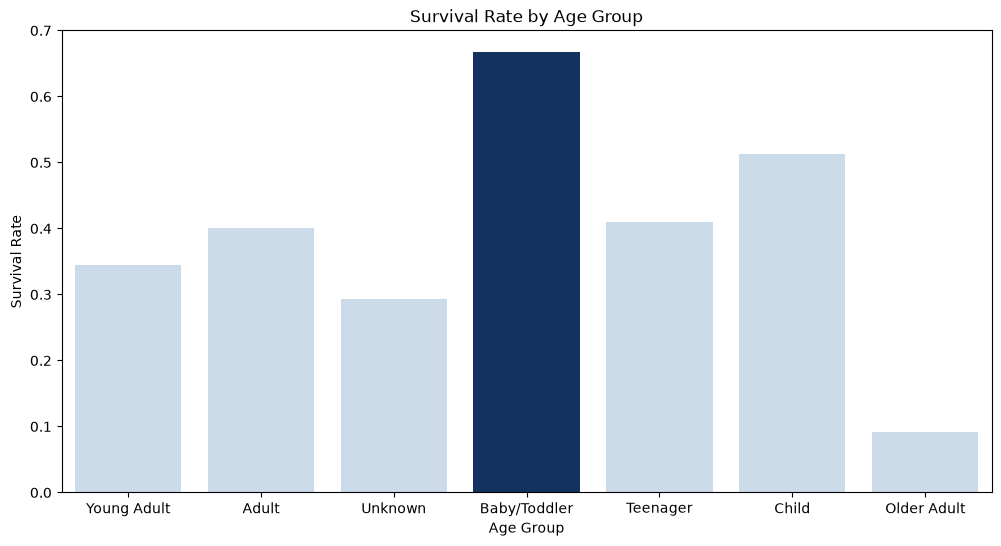

In [66]:
plt.figure(figsize=(12, 6))
plt.ylabel("Survival Rate")
plt.xlabel("Age Group")
plt.title("Survival Rate by Age Group")
sns.barplot(
    data=train,
    x="AgeGroup",
    y="Survived",
    hue="AgeGroup",
    palette={ "Baby/Toddler": "#08306b", "Adult": "#c6dbef", "Young Adult": "#c6dbef", "Teenager": "#c6dbef", "Child": "#c6dbef", "Older Adult": "#c6dbef", "Unknown": "#c6dbef" },
    errorbar= None
)

Add your explanation here:

**Mohammed Grech 10/10/2026**:
The NHS age terminology is used as a basis for AgeGroup feature. This analysis indicates that the survival rate for Baby/Toddler age group was the highest

# Part - 2

## 5) Cleaning Data
It's time to clean the missing values and unnecessary information!

### Looking at the Train Data
Let's see how our test data looks!

**Mohammed Grech 08/10/2026** Initially this meant to be the test data. Due to the reason clarified earlier, the train dataset will be looked into

In [67]:
#test.describe(include="all")
train.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,SibSpGroup,ParchGroup,AgeGroup
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889,891,891,891
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3,2,2,7
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S,Alone,Alone,Adult
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644,608,678,426
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN,NaN,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN,NaN,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN,NaN,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN,NaN,NaN,NaN


* We have a total of 418 passengers.
* 1 value from the Fare feature is missing.
* Around 20.5% of the Age feature is missing, we will need to fill that in.

### Cabin Feature

In [68]:
#we'll start off by dropping the Cabin feature since not a lot more useful information can be extracted from it.
train = train.drop(['Cabin'], axis = 1)

### Ticket Feature
we can also drop the Ticket feature since it's unlikely to yield any useful information.

In [69]:
# Add your code here.
train.drop(['Ticket'], axis = 1, inplace = True)

Dropping the ParchGroup and SibSpGroup columns since they were used for Data Visualization purposes.

In [70]:
train.drop(['ParchGroup'], axis = 1, inplace = True)
train.drop(['SibSpGroup'], axis = 1, inplace = True)

### Embarked Feature
Now we need to fill in the missing values in the Embarked feature.

HINT: It's a good practice to fill in the missing values with the most occurances when the number of missing values are few. But it differs depending on the situation. So, lets replace the missing embarked values with **"S"**, for instance, if the majority of people embarked in Southampton (S). (First find the most frequent one).

In [71]:
# Add your code here
print(train['Embarked'].value_counts().to_string())
print(f"\nNumber of missing values in 'Embarked': {train['Embarked'].isna().sum()}")

Embarked
S    644
C    168
Q     77

Number of missing values in 'Embarked': 2


In [72]:
train['Embarked'] = train['Embarked'].fillna('S')
print(train['Embarked'].value_counts().to_string())

Embarked
S    646
C    168
Q     77


The majority of people embarked in Southampton (S). As a result the missing values which were two records were replaced with "S"

### Age Feature

A higher percentage of values are missing for the age feature. However, it would be illogical to fill all of them with the same value. Instead, we'll try to find a way to predict the missing ages.

In [73]:
#create a combined group of both datasets
# Mohammed Grech 10102026: Since we have no test dataset, I will use the train dataset as a test dataset as well.
test = train.copy()
combine = [train, test]

#extract a title for each Name in the train datasets
for dataset in combine:
    dataset['Title'] = dataset.Name.str.extract(' ([A-Za-z]+)\.', expand=False)

pd.crosstab(train['Title'], train['Sex'])

Sex,female,male
Title,,
Capt,0,1
Col,0,2
Countess,1,0
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40


In [74]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,AgeGroup,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,Young Adult,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,71.2833,C,Adult,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,Adult,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,Adult,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,Adult,Mr


In [75]:
test.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,AgeGroup,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,Young Adult,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,71.2833,C,Adult,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,Adult,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,Adult,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,Adult,Mr


In [76]:
# As the unique values of the Title column are a bit larger than expected, we will replace those with more common terms.
# Replace various titles with more common names
for dataset in combine:
    dataset['Title'] = dataset['Title'].replace(['Lady', 'Capt', 'Col',
    'Don', 'Dr', 'Major', 'Rev', 'Jonkheer', 'Dona'], 'Rare')
    
    dataset['Title'] = dataset['Title'].replace(['Countess', 'Lady', 'Sir'], 'Royal')
    dataset['Title'] = dataset['Title'].replace('Mlle', 'Miss')
    dataset['Title'] = dataset['Title'].replace('Ms', 'Miss')
    dataset['Title'] = dataset['Title'].replace('Mme', 'Mrs')

train[['Title', 'Survived']].groupby(['Title'], as_index=False).mean()

,Title,Survived
0,Master,0.575000
1,Miss,0.702703
2,Mr,0.156673
3,Mrs,0.793651
4,Rare,0.285714
5,Royal,1.000000


In [77]:
# As machine learning model understand numeric values, thus we need to define numerical values for categorical variables.
# Map each of the title groups to a numerical value
title_mapping = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Royal": 5, "Rare": 6}
for dataset in combine:
    dataset['Title'] = dataset['Title'].map(title_mapping)
    dataset['Title'] = dataset['Title'].fillna(0)

train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,AgeGroup,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,Young Adult,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,71.2833,C,Adult,3
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,Adult,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,Adult,3
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,Adult,1


Next, we'll try to predict the missing Age values from the most common age for their Title.

In [78]:
# fill missing age with mode age group for each title
# mr_age = train[train["Title"] == 1]["AgeGroup"].mode() #Young Adult
# miss_age = train[train["Title"] == 2]["AgeGroup"].mode() #Student
# mrs_age = train[train["Title"] == 3]["AgeGroup"].mode() #Adult
# master_age = train[train["Title"] == 4]["AgeGroup"].mode() #Baby
# royal_age = train[train["Title"] == 5]["AgeGroup"].mode() #Adult
# rare_age = train[train["Title"] == 6]["AgeGroup"].mode() #Adult

# age_title_mapping = {1: "Young Adult", 2: "Student", 3: "Adult", 4: "Baby", 5: "Adult", 6: "Adult"}

# #I've put down a less elegant, temporary solution for now. But it's fine for this exercise
# train = train.fillna({"Age": train["Title"].map(age_title_mapping)})
# test = test.fillna({"Age": test["Title"].map(age_title_mapping)})

# for x in range(len(train["AgeGroup"])):
#     if train.loc[x, "AgeGroup"] == "Unknown":
#         train.loc[x, "AgeGroup"] = age_title_mapping[train.loc[x, "Title"]]
        
# for x in range(len(test["AgeGroup"])):
#     if test.loc[x, "AgeGroup"] == "Unknown":
#         test.loc[x, "AgeGroup"] = age_title_mapping[test.loc[x, "Title"]]

**Mohammed Grech 08/10/2026**: 
In my view, the following approach provides a clearer and more concise solution to the code above.


In [79]:
# Calculating median age by title using known ages in train
age_by_title = train.groupby("Title")["Age"].median()

# Filling missing ages in both datasets using those medians
for df in (train, test):
    df["Age"] = df["Age"].fillna(df["Title"].map(age_by_title))


# Create an age range list with their corresponding age group that was defined in the previous section.
#  Get the age of the passenger with unknown group age and assign an age group based on their age.
age_bins = [-float("inf"), 3, 12, 19, 24, 64, float("inf")]
age_labels = [ "Baby/Toddler", "Child", "Teenager", "Young Adult", "Adult", "Older Adult" ]

for df in (train, test):
    df["AgeGroup"] = pd.cut(# pd.cut puts each age into a range. With these bins:
        df["Age"],
        bins=age_bins,
        labels=age_labels,
        include_lowest=True
    ).astype("object")

    df["AgeGroup"] = df["AgeGroup"].fillna("Unknown")

Now that we've filled in the missing values at least somewhat accurately, it's time to map each age group to a numerical value.

In [80]:
# Map each Age value to a numerical value
#age_mapping = {'Baby': 1, 'Child': 2, 'Teenager': 3, 'Student': 4, 'Young Adult': 5, 'Adult': 6, 'Senior': 7}
# Mohammed Grech 08/10/2026: I have changed the age mapping to reflect the new age groups that 
# were defined in the previous section.
age_mapping = { "Baby/Toddler": 1, "Child": 2, "Teenager": 3, "Young Adult": 4, "Adult": 5, "Older Adult": 6, "Unknown": 0 }
train['AgeGroup'] = train['AgeGroup'].map(age_mapping)
test['AgeGroup'] = test['AgeGroup'].map(age_mapping)

train.head()

#dropping the Age feature for now, might change
train = train.drop(['Age'], axis = 1)
test = test.drop(['Age'], axis = 1)

### Name Feature
We can drop the name feature because we've extracted the titles.

In [81]:
#drop the name feature since it contains no more useful information.
train = train.drop(['Name'], axis = 1)
test = test.drop(['Name'], axis = 1)

### Sex Feature

In [82]:
# Map each Sex value to a numerical value
train['Sex'] = train['Sex'].map({'female': 1, 'male': 0}).astype(int)
test['Sex'] = test['Sex'].map({'female': 1, 'male': 0}).astype(int)

### Embarked Feature

In [83]:
# Map each Embarked value to a numerical value
train['Embarked'] = train['Embarked'].map({'S': 0, 'C': 1, 'Q': 2}).astype(int)
test['Embarked'] = test['Embarked'].map({'S': 0, 'C': 1, 'Q': 2}).astype(int)   

### Fare Feature
It's time separate the fare values into some logical groups as well as filling in the single missing value in the test dataset.

In [84]:
#fill in missing Fare value in test set based on mean fare for that Pclass 
# for x in range(len(test["Fare"])):
#     if pd.isnull(test.loc[x, "Fare"]):
#         pclass = test.loc[x, "Pclass"] #Pclass = 3
#         test.loc[x, "Fare"] = round(train[train["Pclass"] == pclass]["Fare"].mean(), 4)

# Mohammed Grech 09/10/2026: There is no missing fare in the train nor in the test dataset. 
# This is because we never used the test.csv dataset as mentioned earlier.
print("Missing fares in train:", train["Fare"].isna().sum())
print("Missing fares in test:", test["Fare"].isna().sum())
        
#map Fare values into groups of numerical values
train['FareBand'] = pd.qcut(train['Fare'], 4, labels = [1, 2, 3, 4])

train["FareBand"], fare_bins = pd.qcut( train["Fare"], 4, labels=[1, 2, 3, 4], retbins=True )

# the test dataset is also updated accordingly.
test["FareBand"] = pd.cut( test["Fare"], bins=fare_bins, labels=[1, 2, 3, 4] )

#drop Fare values
train = train.drop(['Fare'], axis = 1)
test = test.drop(['Fare'], axis = 1)

Missing fares in train: 0
Missing fares in test: 0


In [85]:
#check train data
train.head()

,PassengerId,Survived,Pclass,Sex,SibSp,Parch,Embarked,AgeGroup,Title,FareBand
0,1,0,3,0,1,0,0,4,1,1
1,2,1,1,1,1,0,1,5,3,4
2,3,1,3,1,0,0,0,5,2,2
3,4,1,1,1,1,0,0,5,3,4
4,5,0,3,0,0,0,0,5,1,2


In [86]:
test.head()

,PassengerId,Survived,Pclass,Sex,SibSp,Parch,Embarked,AgeGroup,Title,FareBand
0,1,0,3,0,1,0,0,4,1,1
1,2,1,1,1,1,0,1,5,3,4
2,3,1,3,1,0,0,0,5,2,2
3,4,1,1,1,1,0,0,5,3,4
4,5,0,3,0,0,0,0,5,1,2


**Q:** What differences you are observing here from the initial dataset?

**Mohammed Grech, 09/10/2026**: When compared with the original train.csv, the data has been split into training and testing sets and some of the features have been transformed. The missing Embarked values have been replaced by "S" and the missing Age values have been estimated by using the median age for each passenger title. Age has then been converted into age groups and Fare has been grouped into four fare bands. The categorical features Title, AgeGroup, Sex, and Embarked were encoded numerically. After creating the grouped features, we grouped the original Age and Fare columns. During the cleaning process, Name, Cabin, and Ticket were also removed. Lastly, zero fares have been kept as they were recorded.

**Q:** Write some other ways to change categoriacal variables into numerical ones? (*Hint:* Check scikit-learn preprocessing and encoding documentations):

**Mohammed Grech, 09/10/2026**: Other methods for encoding categorical variables include one-hot encoding, which creates a binary column for each category, and ordinal encoding, which assigns numbers to categories that have a meaningful order. Scikit-learn provides OneHotEncoder and OrdinalEncoder for these methods, which are two commonly used approaches. 

For this dataset, OrdinalEncoder could be considered a suitable approach, as it is similar to the manual process we carried out earlier using dictionaries to map categorical values to numerical values.

OneHotEncoder would also be suitable for categorical features such as Sex and Embarked, as it represents each category independently without implying an order.

There is also LabelEncoder, which can be used to convert target labels (y) into integers (Scikit-learn developers, n.d.).


**Reference**:

Scikit-learn developers (n.d.) Preprocessing data. Available at: https://scikit-learn.org/stable/modules/preprocessing.html (Accessed: 22 October 2026).

## 6) Choosing the Best Model

### Splitting the Training Data
We will use split of our training data into training and validation set to test the accuracy of different models. Please check [here](https://towardsdatascience.com/how-to-split-a-dataset-into-training-and-testing-sets-b146b1649830#:~:text=The%20simplest%20way%20to%20split,the%20performance%20of%20our%20model.) to know more about the reason behind splitting the data 

In [87]:
from sklearn.model_selection import train_test_split
predictors = train.drop(['Survived', 'PassengerId'], axis=1)
target = train["Survived"]
x_train, x_val, y_train, y_val = train_test_split(predictors, target, test_size = 0.20, random_state = 42)

### Testing Different Models
Try to test the following models with the training data

* Support Vector Machines
* Decision Tree Classifier
* Random Forest Classifier
* KNN or k-Nearest Neighbors

For each model, set the model, fit it with 80% of the training data, predict for 20% of the training data and evaluate it using accuracy and other suitable classification measures discussed in the lecture.

Getting the mean of cross validation results

In [88]:
def get_mean_cv_results(cv_results):
    results = pd.DataFrame({
        "Parameters": cv_results["params"],
        "Accuracy": cv_results["mean_test_accuracy"],
        "Misclassification": cv_results["mean_test_mis-classification"],
        "Sensitivity": cv_results["mean_test_sensitivity"],
        "Specificity": cv_results["mean_test_specificity"],
        "Precision": cv_results["mean_test_precision"],
        "F1 score": cv_results["mean_test_f1-score"],
    })

    # These are mean counts per fold, so they may be fractional.
    results["Confusion counts (mean per fold)"] = [
        f"TP={tp:.1f}, TN={tn:.1f}, FP={fp:.1f}, FN={fn:.1f}"
        for tp, tn, fp, fn in zip(
            cv_results["mean_test_TP"],
            cv_results["mean_test_TN"],
            cv_results["mean_test_FP"],
            cv_results["mean_test_FN"]
        )
    ]

    return results

Create score list

In [89]:
# This section creates a score list (evaluation matrix) which will be passed to the RandomizedSearchCV for every classifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, make_scorer,confusion_matrix

# create misclassification score
def misclassification(y_true, y_pred):
    mis_class = 1 - accuracy_score(y_true, y_pred)
    return mis_class

# create confusion matrix scores and pass it to the score list
def true_negative(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn
def false_positive(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp
def false_negative(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fn
def true_positive(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp

# create specificity score
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

# Return the fold's F1 score;
def get_y_values(y_true, y_pred):
    return f1_score(y_true, y_pred, zero_division=0)

# create a dictionary of scores to be used during randomised searching
score_list = {
    'accuracy': make_scorer(accuracy_score),
    'scorer' : make_scorer(get_y_values),
    'mis-classification': make_scorer(misclassification),
    'sensitivity': make_scorer(recall_score),
    'specificity': make_scorer(specificity_score),
    'precision': make_scorer(precision_score),
    'f1-score': make_scorer(f1_score),
    'TP': make_scorer(true_positive),
    'TN': make_scorer(true_negative),
    'FP': make_scorer(false_positive),
    'FN': make_scorer(false_negative)
}

Function to plot evaluation matrix for best estimator

In [90]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix"):
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=[0, 1],
        display_labels=["Did not survive", "Survived"],
        cmap="Blues",
        values_format="d"
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [91]:
from sklearn.model_selection import StratifiedKFold

#Global variables
iter_no = 20
fold_no= 5
validation_scores = {}

skf = StratifiedKFold(n_splits=fold_no, shuffle=True, random_state=42)

## Support Vector Machines (SVM)

In [92]:
# Add your code here.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report

svm_model = make_pipeline(
    StandardScaler(),
    SVC()
)

SVM_params = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': [0.001, 0.01, 0.1, 1],
    'svc__kernel': ['linear', 'rbf', 'poly'],
    'svc__class_weight': [None, 'balanced']
}

# Create RandomizedSearchCV
SVM_clf = RandomizedSearchCV(
    estimator=svm_model,
    param_distributions=SVM_params, 
    scoring=score_list, 
    refit='f1-score',
    n_iter=iter_no, 
    cv=skf, 
    random_state=42, 
    n_jobs=8 # My machine has 8 cores, so I will use all of them to speed up the process.
)

# Fit the search using training data only
SVM_clf.fit(x_train, y_train)
best_svm_model = SVM_clf.best_estimator_
best_index = SVM_clf.best_index_

In [93]:
get_mean_cv_results(SVM_clf.cv_results_)

,Parameters,Accuracy,Misclassification,Sensitivity,Specificity,Precision,F1 score,Confusion counts (mean per fold)
0,"{'svc__kernel': 'poly', 'svc__gamma': 0.1, 'svc__class_weight': None, 'svc__C': 100}",0.804757,0.195243,0.664221,0.889709,0.785700,0.716809,"TP=35.6, TN=79.0, FP=9.8, FN=18.0"
1,"{'svc__kernel': 'poly', 'svc__gamma': 0.01, 'svc__class_weight': None, 'svc__C': 100}",0.768266,0.231734,0.429140,0.972983,0.904609,0.581053,"TP=23.0, TN=86.4, FP=2.4, FN=30.6"
2,"{'svc__kernel': 'rbf', 'svc__gamma': 0.001, 'svc__class_weight': None, 'svc__C': 100}",0.799173,0.200827,0.701607,0.858069,0.749572,0.724198,"TP=37.6, TN=76.2, FP=12.6, FN=16.0"
3,"{'svc__kernel': 'rbf', 'svc__gamma': 1, 'svc__class_weight': 'balanced', 'svc__C': 100}",0.800532,0.199468,0.764990,0.822063,0.722513,0.742723,"TP=41.0, TN=73.0, FP=15.8, FN=12.6"
4,"{'svc__kernel': 'linear', 'svc__gamma': 1, 'svc__class_weight': None, 'svc__C': 1}",0.782311,0.217689,0.686653,0.840066,0.720947,0.703183,"TP=36.8, TN=74.6, FP=14.2, FN=16.8"
5,"{'svc__kernel': 'rbf', 'svc__gamma': 0.1, 'svc__class_weight': None, 'svc__C': 100}",0.803359,0.196641,0.671488,0.882916,0.777500,0.718006,"TP=36.0, TN=78.4, FP=10.4, FN=17.6"
6,"{'svc__kernel': 'linear', 'svc__gamma': 1, 'svc__class_weight': 'balanced', 'svc__C': 10}",0.806176,0.193824,0.746331,0.842314,0.740248,0.743057,"TP=40.0, TN=74.8, FP=14.0, FN=13.6"
7,"{'svc__kernel': 'linear', 'svc__gamma': 0.1, 'svc__class_weight': 'balanced', 'svc__C': 1}",0.804767,0.195233,0.746331,0.840041,0.737650,0.741722,"TP=40.0, TN=74.6, FP=14.2, FN=13.6"
8,"{'svc__kernel': 'linear', 'svc__gamma': 0.001, 'svc__class_weight': None, 'svc__C': 0.1}",0.779494,0.220506,0.682879,0.837794,0.716842,0.699167,"TP=36.6, TN=74.4, FP=14.4, FN=17.0"
9,"{'svc__kernel': 'rbf', 'svc__gamma': 1, 'svc__class_weight': None, 'svc__C': 0.1}",0.712085,0.287915,0.253739,0.988764,0.928947,0.396111,"TP=13.6, TN=87.8, FP=1.0, FN=40.0"


In [94]:
print("Best parameters:", SVM_clf.best_params_)
print(f"Mean CV accuracy: {SVM_clf.cv_results_['mean_test_accuracy'][best_index]:.3f}")
print(f"Mean CV F1: {SVM_clf.cv_results_['mean_test_f1-score'][best_index]:.3f}")
print(f"Best index: {SVM_clf.best_index_}")

# Predicting on the holdout validation set using the best SVM model
y_pred = best_svm_model.predict(x_val)
SVM_accuracy_score = accuracy_score(y_val, y_pred)

print(f"Validation accuracy: {SVM_accuracy_score:.3f}")

report = classification_report(
    y_val,
    y_pred,
    labels=[0, 1],
    target_names=["Did not survive", "Survived"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_df.head()

Best parameters: {'svc__kernel': 'rbf', 'svc__gamma': 0.1, 'svc__class_weight': None, 'svc__C': 1}
Mean CV accuracy: 0.837
Mean CV F1: 0.768
Best index: 14
Validation accuracy: 0.821


,precision,recall,f1-score,support
Did not survive,0.828829,0.876190,0.851852,105.000000
Survived,0.808824,0.743243,0.774648,74.000000
accuracy,0.821229,0.821229,0.821229,0.821229
macro avg,0.818826,0.809717,0.813250,179.000000
weighted avg,0.820558,0.821229,0.819935,179.000000


In [95]:
import joblib

# Save the best model
model_filename = f"SVM_model_{SVM_accuracy_score:.3f}.joblib"
joblib.dump(best_svm_model, model_filename)

# store the validation score on the holdout data.
validation_scores["SVM"] = {
    "Accuracy": accuracy_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Best parameters": SVM_clf.best_params_
}

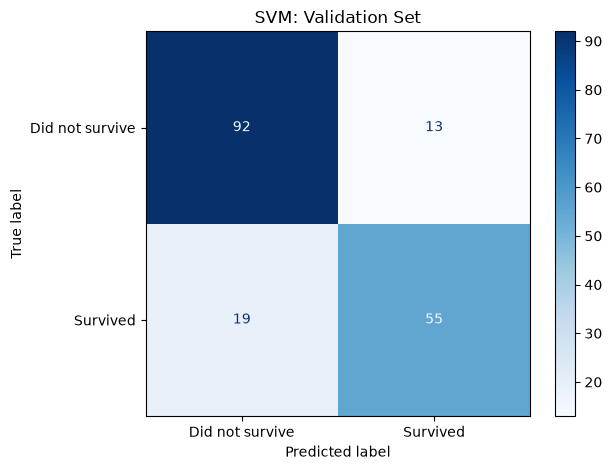

In [96]:
plot_confusion_matrix(y_val, y_pred, title="SVM: Validation Set")

# Decision Tree Classifier (DT)

In [97]:
from scipy.stats import randint
from sklearn.tree import DecisionTreeClassifier

from scipy.stats import randint, uniform

DT_params = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, *range(3, 16)],
    "min_samples_split": randint(2, 21),
    "min_samples_leaf": randint(1, 16),
    "max_features": [None, "sqrt", "log2"],
    "class_weight": [None, "balanced"],
    "ccp_alpha": uniform(0, 0.02)
}

DT=DecisionTreeClassifier(random_state=42)
DT_clf = RandomizedSearchCV(
    estimator=DT,
    param_distributions=DT_params,
    scoring=score_list, 
    refit='f1-score',
    n_iter=iter_no, 
    cv=skf, 
    random_state=20,
    n_jobs=8
)

DT_clf.fit(x_train, y_train)
best_DT_model = DT_clf.best_estimator_
best_index = DT_clf.best_index_

In [98]:
get_mean_cv_results(DT_clf.cv_results_)

,Parameters,Accuracy,Misclassification,Sensitivity,Specificity,Precision,F1 score,Confusion counts (mean per fold)
0,"{'ccp_alpha': 0.011762616021545484, 'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 14, 'max_features': 'log2', 'min_samples_leaf': 10, 'min_samples_split': 13}",0.800561,0.199439,0.686443,0.869203,0.765142,0.720580,"TP=36.8, TN=77.2, FP=11.6, FN=16.8"
1,"{'ccp_alpha': 0.01280711065109932, 'class_weight': None, 'criterion': 'gini', 'max_depth': 8, 'max_features': None, 'min_samples_leaf': 6, 'min_samples_split': 18}",0.799163,0.200837,0.610971,0.912079,0.832280,0.690728,"TP=32.8, TN=81.0, FP=7.8, FN=20.8"
2,"{'ccp_alpha': 0.015650228220016646, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'min_samples_split': 9}",0.796326,0.203674,0.518658,0.963968,0.900075,0.655498,"TP=27.8, TN=85.6, FP=3.2, FN=25.8"
3,"{'ccp_alpha': 0.006310484265784069, 'class_weight': None, 'criterion': 'gini', 'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 12, 'min_samples_split': 5}",0.796307,0.203693,0.604682,0.912232,0.818062,0.686343,"TP=32.4, TN=81.0, FP=7.8, FN=21.2"
4,"{'ccp_alpha': 0.005441025325302114, 'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 15, 'min_samples_split': 16}",0.783680,0.216320,0.690147,0.839913,0.726655,0.706334,"TP=37.0, TN=74.6, FP=14.2, FN=16.6"
5,"{'ccp_alpha': 0.0036984553590792314, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 13, 'max_features': 'log2', 'min_samples_leaf': 4, 'min_samples_split': 15}",0.797784,0.202216,0.735010,0.835674,0.731577,0.731290,"TP=39.4, TN=74.2, FP=14.6, FN=14.2"
6,"{'ccp_alpha': 0.009220787925848614, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 12, 'min_samples_split': 9}",0.792121,0.207879,0.682600,0.858095,0.752005,0.712160,"TP=36.6, TN=76.2, FP=12.6, FN=17.0"
7,"{'ccp_alpha': 0.004829695532817342, 'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8, 'max_features': 'log2', 'min_samples_leaf': 9, 'min_samples_split': 20}",0.797715,0.202285,0.724039,0.842135,0.738695,0.729440,"TP=38.8, TN=74.8, FP=14.0, FN=14.8"
8,"{'ccp_alpha': 0.010212821123503036, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 7, 'min_samples_split': 11}",0.808992,0.191008,0.526415,0.979775,0.948199,0.671312,"TP=28.2, TN=87.0, FP=1.8, FN=25.4"
9,"{'ccp_alpha': 0.0009808429060249857, 'class_weight': None, 'criterion': 'gini', 'max_depth': 13, 'max_features': None, 'min_samples_leaf': 7, 'min_samples_split': 17}",0.818822,0.181178,0.634312,0.930235,0.847555,0.724114,"TP=34.0, TN=82.6, FP=6.2, FN=19.6"


In [99]:
print("Best parameters:", DT_clf.best_params_)
print(f"Mean CV accuracy: {DT_clf.cv_results_['mean_test_accuracy'][best_index]:.3f}")
print(f"Mean CV F1: {DT_clf.cv_results_['mean_test_f1-score'][best_index]:.3f}")
print(f"Best index: {DT_clf.best_index_}")

# Predicting on the holdout validation set using the best DT model
y_pred = best_DT_model.predict(x_val)
DT_accuracy_score = accuracy_score(y_val, y_pred)

print(f"Validation accuracy: {DT_accuracy_score:.3f}")
report = classification_report(
    y_val,
    y_pred,
    labels=[0, 1],
    target_names=["Did not survive", "Survived"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_df.head()

Best parameters: {'ccp_alpha': np.float64(0.007439099611139808), 'class_weight': None, 'criterion': 'gini', 'max_depth': 14, 'max_features': None, 'min_samples_leaf': 12, 'min_samples_split': 6}
Mean CV accuracy: 0.823
Mean CV F1: 0.744
Best index: 11
Validation accuracy: 0.821


,precision,recall,f1-score,support
Did not survive,0.841121,0.857143,0.849057,105.000000
Survived,0.791667,0.770270,0.780822,74.000000
accuracy,0.821229,0.821229,0.821229,0.821229
macro avg,0.816394,0.813707,0.814939,179.000000
weighted avg,0.820676,0.821229,0.820848,179.000000


In [100]:
# Save the best model
model_filename = f"DT_model_{DT_accuracy_score:.3f}.joblib"
joblib.dump(best_DT_model, model_filename)

validation_scores["Decision Tree"] = {
    "Accuracy": accuracy_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Best parameters": DT_clf.best_params_
}

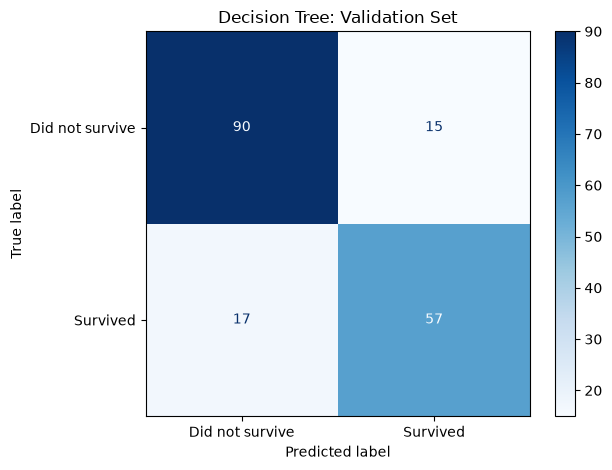

In [101]:
plot_confusion_matrix(y_val, y_pred, title="Decision Tree: Validation Set")

# Random Forest Classifier

In [102]:
from sklearn.ensemble import RandomForestClassifier

RF_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced'],
    'bootstrap': [True, False]
}

RF = RandomForestClassifier(random_state=42)
RF_clf = RandomizedSearchCV(
    estimator=RF, 
    param_distributions=RF_params, 
    scoring=score_list, 
    refit='f1-score',
    n_iter=iter_no, 
    cv=skf, 
    random_state=20,
    n_jobs=8
)
RF_clf.fit(x_train, y_train)
best_RF_model = RF_clf.best_estimator_
best_index = RF_clf.best_index_

In [103]:
get_mean_cv_results(RF_clf.cv_results_)

,Parameters,Accuracy,Misclassification,Sensitivity,Specificity,Precision,F1 score,Confusion counts (mean per fold)
0,"{'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 5, 'class_weight': 'balanced', 'bootstrap': False}",0.818812,0.181188,0.738924,0.867109,0.773536,0.754549,"TP=39.6, TN=77.0, FP=11.8, FN=14.0"
1,"{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 15, 'class_weight': 'balanced', 'bootstrap': False}",0.813188,0.186812,0.742837,0.856001,0.764700,0.749041,"TP=39.8, TN=76.0, FP=12.8, FN=13.8"
2,"{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': 'balanced', 'bootstrap': False}",0.817394,0.182606,0.765059,0.849157,0.756558,0.759351,"TP=41.0, TN=75.4, FP=13.4, FN=12.6"
3,"{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 15, 'class_weight': None, 'bootstrap': True}",0.841278,0.158722,0.705381,0.923493,0.853636,0.769558,"TP=37.8, TN=82.0, FP=6.8, FN=15.8"
4,"{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 15, 'class_weight': None, 'bootstrap': True}",0.834256,0.165744,0.682949,0.925715,0.848778,0.755097,"TP=36.6, TN=82.2, FP=6.6, FN=17.0"
5,"{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 5, 'class_weight': 'balanced', 'bootstrap': False}",0.820221,0.179779,0.738924,0.869356,0.775956,0.755859,"TP=39.6, TN=77.2, FP=11.6, FN=14.0"
6,"{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': 'balanced', 'bootstrap': False}",0.823018,0.176982,0.776310,0.851456,0.764731,0.767895,"TP=41.6, TN=75.6, FP=13.2, FN=12.0"
7,"{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 15, 'class_weight': 'balanced', 'bootstrap': True}",0.818812,0.181188,0.723969,0.876226,0.783712,0.749891,"TP=38.8, TN=77.8, FP=11.0, FN=14.8"
8,"{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': 'balanced', 'bootstrap': True}",0.817423,0.182577,0.738784,0.864939,0.769704,0.752529,"TP=39.6, TN=76.8, FP=12.0, FN=14.0"
9,"{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': 'balanced', 'bootstrap': True}",0.824416,0.175584,0.742628,0.873825,0.783413,0.761251,"TP=39.8, TN=77.6, FP=11.2, FN=13.8"


In [104]:
print("Best parameters:", RF_clf.best_params_)
print(f"Mean CV accuracy: {RF_clf.cv_results_['mean_test_accuracy'][best_index]:.3f}")
print(f"Mean CV F1: {RF_clf.cv_results_['mean_test_f1-score'][best_index]:.3f}")
print(f"Best index: {RF_clf.best_index_}")

# Predicting on the holdout validation set using the best Random Forest model
y_pred = best_RF_model.predict(x_val)
RF_accuracy_score = accuracy_score(y_val, y_pred)

print(f"Validation accuracy: {RF_accuracy_score:.3f}")
report = classification_report(
    y_val,
    y_pred,
    labels=[0, 1],
    target_names=["Did not survive", "Survived"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_df.head()

Best parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 15, 'class_weight': None, 'bootstrap': True}
Mean CV accuracy: 0.841
Mean CV F1: 0.770
Best index: 3
Validation accuracy: 0.827


,precision,recall,f1-score,support
Did not survive,0.830357,0.885714,0.857143,105.000000
Survived,0.820896,0.743243,0.780142,74.000000
accuracy,0.826816,0.826816,0.826816,0.826816
macro avg,0.825626,0.814479,0.818642,179.000000
weighted avg,0.826446,0.826816,0.825310,179.000000


In [105]:
# Save the best model
model_filename = f"RF_model_{RF_accuracy_score:.3f}.joblib"
joblib.dump(best_RF_model, model_filename)

validation_scores["Random Forest"] = {
    "Accuracy": accuracy_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Best parameters": RF_clf.best_params_
}

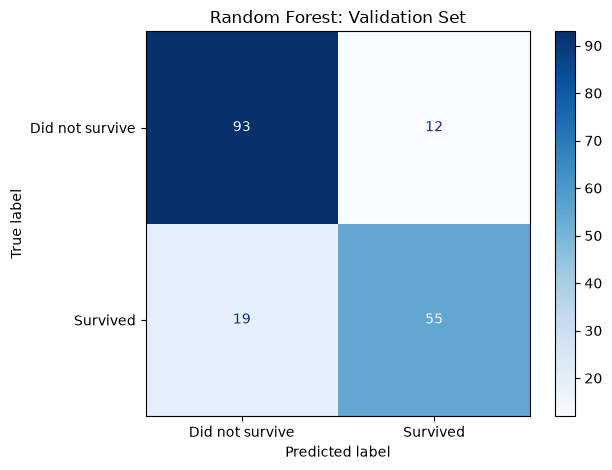

In [106]:
plot_confusion_matrix(y_val, y_pred, title="Random Forest: Validation Set")

# KNN or k-Nearest Neighbors

In [107]:
from sklearn.neighbors import KNeighborsClassifier

KNN_params = {
    'n_neighbors': np.arange(1, 51),
    'leaf_size': (20,40,1),
    'weights': ['uniform', 'distance'],
     'p': (1,2), 
    'metric': ['euclidean', 'manhattan', 'chebyshev']
}

KNN = KNeighborsClassifier()
KNN_clf = RandomizedSearchCV(
    estimator=KNN, 
    param_distributions=KNN_params, 
    scoring=score_list, 
    refit='f1-score',
    n_iter=iter_no, 
    cv=skf, 
    random_state=20
)

KNN_clf.fit(x_train, y_train)
best_KNN_model = KNN_clf.best_estimator_
best_index = KNN_clf.best_index_

In [108]:
get_mean_cv_results(KNN_clf.cv_results_)

,Parameters,Accuracy,Misclassification,Sensitivity,Specificity,Precision,F1 score,Confusion counts (mean per fold)
0,"{'weights': 'uniform', 'p': 1, 'n_neighbors': 35, 'metric': 'euclidean', 'leaf_size': 20}",0.818812,0.181188,0.671628,0.907584,0.816568,0.735261,"TP=36.0, TN=80.6, FP=8.2, FN=17.6"
1,"{'weights': 'distance', 'p': 1, 'n_neighbors': 28, 'metric': 'manhattan', 'leaf_size': 20}",0.811780,0.188220,0.664011,0.900894,0.803529,0.724443,"TP=35.6, TN=80.0, FP=8.8, FN=18.0"
2,"{'weights': 'distance', 'p': 2, 'n_neighbors': 44, 'metric': 'euclidean', 'leaf_size': 20}",0.803378,0.196622,0.664081,0.887360,0.786333,0.717006,"TP=35.6, TN=78.8, FP=10.0, FN=18.0"
3,"{'weights': 'distance', 'p': 2, 'n_neighbors': 20, 'metric': 'manhattan', 'leaf_size': 40}",0.810371,0.189629,0.664011,0.898647,0.802208,0.723110,"TP=35.6, TN=79.8, FP=9.0, FN=18.0"
4,"{'weights': 'uniform', 'p': 2, 'n_neighbors': 17, 'metric': 'manhattan', 'leaf_size': 20}",0.821609,0.178391,0.694060,0.898698,0.805188,0.745007,"TP=37.2, TN=79.8, FP=9.0, FN=16.4"
5,"{'weights': 'distance', 'p': 1, 'n_neighbors': 4, 'metric': 'euclidean', 'leaf_size': 20}",0.806156,0.193844,0.615584,0.921118,0.828220,0.704309,"TP=33.0, TN=81.8, FP=7.0, FN=20.6"
6,"{'weights': 'distance', 'p': 2, 'n_neighbors': 21, 'metric': 'manhattan', 'leaf_size': 40}",0.811780,0.188220,0.660238,0.903141,0.807355,0.723491,"TP=35.4, TN=80.2, FP=8.6, FN=18.2"
7,"{'weights': 'distance', 'p': 2, 'n_neighbors': 1, 'metric': 'chebyshev', 'leaf_size': 20}",0.752802,0.247198,0.608526,0.840015,0.700311,0.649981,"TP=32.6, TN=74.6, FP=14.2, FN=21.0"
8,"{'weights': 'uniform', 'p': 2, 'n_neighbors': 35, 'metric': 'manhattan', 'leaf_size': 20}",0.830040,0.169960,0.709085,0.903090,0.816175,0.756889,"TP=38.0, TN=80.2, FP=8.6, FN=15.6"
9,"{'weights': 'distance', 'p': 2, 'n_neighbors': 31, 'metric': 'manhattan', 'leaf_size': 40}",0.808963,0.191037,0.667715,0.894152,0.795283,0.722824,"TP=35.8, TN=79.4, FP=9.4, FN=17.8"


In [109]:
print("Best parameters:", KNN_clf.best_params_)
print(f"Mean CV accuracy: {KNN_clf.cv_results_['mean_test_accuracy'][best_index]:.3f}")
print(f"Mean CV F1: {KNN_clf.cv_results_['mean_test_f1-score'][best_index]:.3f}")
print(f"Best index: {KNN_clf.best_index_}")

# Predicting on the holdout validation set using the best KNN model
y_pred = best_KNN_model.predict(x_val)
KNN_accuracy_score = accuracy_score(y_val, y_pred)

print(f"Validation accuracy: {KNN_accuracy_score:.3f}")
report = classification_report(
    y_val,
    y_pred,
    labels=[0, 1],
    target_names=["Did not survive", "Survived"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
report_df.head()

Best parameters: {'weights': 'uniform', 'p': 2, 'n_neighbors': np.int64(35), 'metric': 'manhattan', 'leaf_size': 20}
Mean CV accuracy: 0.830
Mean CV F1: 0.757
Best index: 8
Validation accuracy: 0.816


,precision,recall,f1-score,support
Did not survive,0.815789,0.885714,0.849315,105.000000
Survived,0.815385,0.716216,0.762590,74.000000
accuracy,0.815642,0.815642,0.815642,0.815642
macro avg,0.815587,0.800965,0.805952,179.000000
weighted avg,0.815622,0.815642,0.813462,179.000000


In [110]:
# Save the best model
model_filename = f"KNN_model_{KNN_accuracy_score:.3f}.joblib"
joblib.dump(best_KNN_model, model_filename)

validation_scores["KNN"] = {
    "Accuracy": accuracy_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Best parameters": KNN_clf.best_params_
}

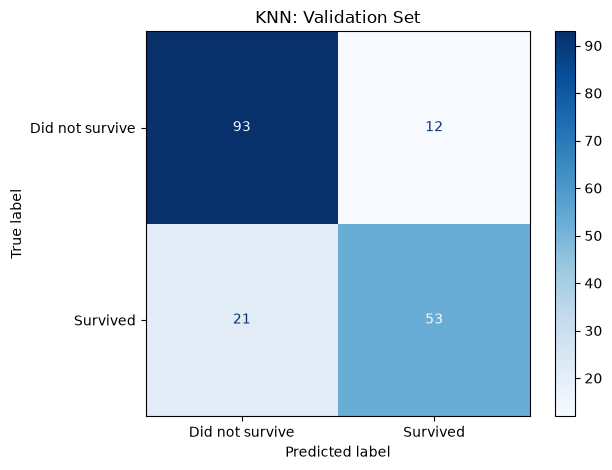

In [111]:
plot_confusion_matrix(y_val, y_pred, title="KNN: Validation Set")

# Dispalying best model

In [112]:
for name, metrics in validation_scores.items():
    print(
        f"{name}: "
        f"accuracy={metrics['Accuracy']:.3f}, "
        f"F1={metrics['F1']:.3f}, "
        f"recall={metrics['Recall']:.3f}, "
        f"precision={metrics['Precision']:.3f}"
    )

# Select the model with the highest validation accuracy
best_model_name = max(
    validation_scores,
    key=lambda name: validation_scores[name]["Accuracy"]
)
best_model_results = validation_scores[best_model_name]

best_result_df = pd.DataFrame([{
    "Best model": best_model_name,
    "Validation accuracy": best_model_results["Accuracy"],
    "Validation F1": best_model_results["F1"],
    "Validation recall": best_model_results["Recall"],
    "Validation precision": best_model_results["Precision"],
    "Best parameters": best_model_results["Best parameters"]
}])

pd.set_option("display.max_colwidth", None)

best_result_df.round({
    "Validation accuracy": 3,
    "Validation F1": 3,
    "Validation recall": 3,
    "Validation precision": 3
})

SVM: accuracy=0.821, F1=0.775, recall=0.743, precision=0.809
Decision Tree: accuracy=0.821, F1=0.781, recall=0.770, precision=0.792
Random Forest: accuracy=0.827, F1=0.780, recall=0.743, precision=0.821
KNN: accuracy=0.816, F1=0.763, recall=0.716, precision=0.815


,Best model,Validation accuracy,Validation F1,Validation recall,Validation precision,Best parameters
0,Random Forest,0.827,0.78,0.743,0.821,"{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 15, 'class_weight': None, 'bootstrap': True}"


**Q:** Compare all the above models and draw a conclusion which model should we use and why!

**Mohammed Grech 10/10/2026:** Random Forest achieved the highest validation accuracy (0.827) and precision (0.821), while Decision Tree achieved the highest F1-score (0.781) and recall (0.770) for the “Survived” class. The differences between the two models are small. Random Forest is preferable when overall accuracy and minimising false survivor predictions are priorities. However, if identifying as many actual survivors as possible is more important, Decision Tree is the better choice since it has the highest recall.
KNN performed worst in terms of accuracy, F1-score and recall, making it the least suitable model among the four tested.
